# TESS CNN Low Gaussian Noise Audio Emotion Recognition = 5% noise



## 1. Project Setup




In [1]:
import os
import re
import json
import time
import pickle
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display
import soundfile as sf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.manifold import TSNE

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: []


## Runtime Timer

This small timer measures the full notebook pipeline runtime.

It starts before dataset scanning, preprocessing, feature loading/creation, training, evaluation, plots, and saving files.


In [2]:
# Start timing the full notebook/model pipeline.
# This is different from the shorter training time measured only around model.fit().
WHOLE_PIPELINE_START_TIME = time.time()


## 2. Configuration




In [3]:
# This is your local TESS dataset folder.
DATASET_PATH = Path(r"D:\Deep Lerning\project\new projects\Toronto emotional speech set (TESS)\TESS")
MODEL_DISPLAY_NAME = "CNN Low Gaussian Noise"

# This version saves files in its own folder so it does not overwrite the clean CNN.
MODEL_FAMILY = "cnn_low_gaussian_noise"
PROJECT_OUTPUT_DIR = Path("outputs")
OUTPUT_DIR = PROJECT_OUTPUT_DIR / MODEL_FAMILY
LIVE_RECORDINGS_DIR = OUTPUT_DIR / "live_recordings"
MODEL_RUNS_DIR = OUTPUT_DIR / "model_runs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LIVE_RECORDINGS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_RUNS_DIR.mkdir(parents=True, exist_ok=True)

# Audio settings.

SAMPLE_RATE = 22050
DURATION_SECONDS = 3.0
LIVE_RECORD_SECONDS = 5
N_MELS = 128

# Noise setting for this notebook.
# Low Gaussian noise is added to every audio file after volume normalization.
ADD_GAUSSIAN_NOISE = True
GAUSSIAN_NOISE_STD = 0.05

# Training settings.
RANDOM_STATE = 42
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15
EPOCHS = 50

# Cache file for noisy spectrograms.
# This cache is separate from the clean CNN cache.
FEATURE_CACHE_PATH = OUTPUT_DIR / "features_cache_low_gaussian_noise.npz"

# Saved model files.
BEST_MODEL_PATH = OUTPUT_DIR / "best_cnn_low_gaussian_noise_model.keras"
LABEL_ENCODER_PATH = OUTPUT_DIR / "label_encoder.pkl"

# We set seeds so results are easier to repeat.
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Dataset path:", DATASET_PATH)
print("Output folder:", OUTPUT_DIR.resolve())
print("Gaussian noise enabled:", ADD_GAUSSIAN_NOISE)
print("Gaussian noise standard deviation:", GAUSSIAN_NOISE_STD)


Dataset path: D:\Deep Lerning\project\new projects\Toronto emotional speech set (TESS)\TESS
Output folder: C:\Users\asus\OneDrive\Desktop\deep paper\submited\data and code\code\outputs\cnn_low_gaussian_noise
Gaussian noise enabled: True
Gaussian noise standard deviation: 0.05


## 3. Scan the TESS Dataset




In [4]:
def clean_emotion_name(text):
    # Turn folder/file emotion names into one clean label.
    text = text.lower().replace("-", "_").replace(" ", "_")

    if "pleasant" in text or text.endswith("_ps") or text == "ps":
        return "pleasant_surprise"
    if "angry" in text or "anger" in text:
        return "angry"
    if "disgust" in text:
        return "disgust"
    if "fear" in text:
        return "fear"
    if "happy" in text or "happiness" in text:
        return "happy"
    if "neutral" in text:
        return "neutral"
    if "sad" in text or "sadness" in text:
        return "sad"

    return "unknown"


def get_speaker_name(file_path):
    # Find whether the audio is from OAF or YAF.
    name = file_path.stem.upper()
    folder = file_path.parent.name.upper()

    if name.startswith("OAF") or folder.startswith("OAF"):
        return "OAF"
    if name.startswith("YAF") or folder.startswith("YAF"):
        return "YAF"
    return "unknown"


def get_word_name(file_path):
    # Extract the spoken word from names like OAF_back_angry.wav.
    name = file_path.stem
    parts = name.split("_")

    # Example: OAF_back_angry -> word is "back".
    if len(parts) >= 3:
        return "_".join(parts[1:-1])
    return "unknown"


def scan_tess_dataset(dataset_path):
    # Create a table where each row is one audio file.
    if not dataset_path.exists():
        raise FileNotFoundError(f"Dataset folder was not found: {dataset_path}")

    rows = []
    wav_files = sorted(dataset_path.rglob("*.wav"))

    for file_path in wav_files:
        emotion_from_folder = clean_emotion_name(file_path.parent.name)
        emotion_from_file = clean_emotion_name(file_path.stem)
        emotion = emotion_from_folder if emotion_from_folder != "unknown" else emotion_from_file

        rows.append({
            "file_path": str(file_path),
            "file_name": file_path.name,
            "folder": file_path.parent.name,
            "speaker": get_speaker_name(file_path),
            "word": get_word_name(file_path),
            "emotion": emotion,
        })

    return pd.DataFrame(rows)


metadata_df = scan_tess_dataset(DATASET_PATH)
metadata_df.head()

,file_path,file_name,folder,speaker,word,emotion
0,D:\Deep Lerning\project\new projects\Toronto e...,OAF_back_angry.wav,OAF_angry,OAF,back,angry
1,D:\Deep Lerning\project\new projects\Toronto e...,OAF_bar_angry.wav,OAF_angry,OAF,bar,angry
2,D:\Deep Lerning\project\new projects\Toronto e...,OAF_base_angry.wav,OAF_angry,OAF,base,angry
3,D:\Deep Lerning\project\new projects\Toronto e...,OAF_bath_angry.wav,OAF_angry,OAF,bath,angry
4,D:\Deep Lerning\project\new projects\Toronto e...,OAF_bean_angry.wav,OAF_angry,OAF,bean,angry


## 4. Dataset Statistics




In [5]:
def add_audio_statistics(df, compute_signal_features=True):
    # Add many audio statistics for every file in the dataset.
    rows = []

    for index, row in df.iterrows():
        path = Path(row["file_path"])
        info = sf.info(path)

        # These values come from the audio file header.
        audio_row = {
            **row.to_dict(),
            "file_extension": path.suffix.lower(),
            "file_size_kb": path.stat().st_size / 1024,
            "duration_seconds": info.duration,
            "original_sample_rate": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "audio_format": info.format,
            "audio_subtype": info.subtype,
            "bitrate_kbps_estimate": (path.stat().st_size * 8 / 1000) / max(info.duration, 1e-8),
        }

        if compute_signal_features:
            # These values come from the actual sound wave.
            # We load with sr=None so we inspect the original audio first.
            audio, sr = librosa.load(path, sr=None, mono=True)

            # RMS is a simple volume/energy measure.
            audio_row["rms_energy_mean"] = float(np.mean(librosa.feature.rms(y=audio)))

            # Zero-crossing rate counts how often the wave crosses zero.
            # Speech with sharper/noisier sounds can have a higher value.
            audio_row["zero_crossing_rate_mean"] = float(np.mean(librosa.feature.zero_crossing_rate(audio)))

            # Spectral centroid is like the "center of brightness" of the sound.
            audio_row["spectral_centroid_mean"] = float(np.mean(librosa.feature.spectral_centroid(y=audio, sr=sr)))

            # Spectral bandwidth tells us how spread out the frequencies are.
            audio_row["spectral_bandwidth_mean"] = float(np.mean(librosa.feature.spectral_bandwidth(y=audio, sr=sr)))
        else:
            audio_row["rms_energy_mean"] = np.nan
            audio_row["zero_crossing_rate_mean"] = np.nan
            audio_row["spectral_centroid_mean"] = np.nan
            audio_row["spectral_bandwidth_mean"] = np.nan

        rows.append(audio_row)

        if (index + 1) % 300 == 0:
            print(f"Checked {index + 1}/{len(df)} audio files")

    return pd.DataFrame(rows)


def make_grouped_audio_summary(df, group_column):
    # Make a summary table for one category, such as emotion or speaker.
    summary = (
        df.groupby(group_column)
        .agg(
            files=("file_path", "count"),
            duration_mean=("duration_seconds", "mean"),
            duration_min=("duration_seconds", "min"),
            duration_max=("duration_seconds", "max"),
            file_size_kb_mean=("file_size_kb", "mean"),
            rms_energy_mean=("rms_energy_mean", "mean"),
            zero_crossing_rate_mean=("zero_crossing_rate_mean", "mean"),
            spectral_centroid_mean=("spectral_centroid_mean", "mean"),
            spectral_bandwidth_mean=("spectral_bandwidth_mean", "mean"),
        )
        .reset_index()
        .sort_values("files", ascending=False)
    )
    return summary


metadata_df = add_audio_statistics(metadata_df, compute_signal_features=True)

# Save one row per audio file.
metadata_df.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)

# Save summaries from different views of the same audio dataset.
emotion_summary_df = make_grouped_audio_summary(metadata_df, "emotion")
speaker_summary_df = make_grouped_audio_summary(metadata_df, "speaker")
word_summary_df = make_grouped_audio_summary(metadata_df, "word")

audio_type_summary_df = (
    metadata_df.groupby(["file_extension", "audio_format", "audio_subtype", "channels", "original_sample_rate"])
    .agg(
        files=("file_path", "count"),
        duration_mean=("duration_seconds", "mean"),
        duration_min=("duration_seconds", "min"),
        duration_max=("duration_seconds", "max"),
        file_size_kb_mean=("file_size_kb", "mean"),
        bitrate_kbps_estimate_mean=("bitrate_kbps_estimate", "mean"),
    )
    .reset_index()
    .sort_values("files", ascending=False)
)

emotion_summary_df.to_csv(OUTPUT_DIR / "emotion_audio_statistics.csv", index=False)
speaker_summary_df.to_csv(OUTPUT_DIR / "speaker_audio_statistics.csv", index=False)
word_summary_df.to_csv(OUTPUT_DIR / "word_audio_statistics.csv", index=False)
audio_type_summary_df.to_csv(OUTPUT_DIR / "audio_type_statistics.csv", index=False)

print("Total audio files:", len(metadata_df))
print("Number of emotions:", metadata_df["emotion"].nunique())
print("Number of speakers:", metadata_df["speaker"].nunique())
print("Number of spoken words:", metadata_df["word"].nunique())

print("\nFiles per emotion:")
display(metadata_df["emotion"].value_counts().sort_index().to_frame("files"))

print("\nAudio technical types:")
display(audio_type_summary_df)

print("\nDuration statistics:")
display(metadata_df["duration_seconds"].describe().to_frame("duration_seconds"))

print("\nEmotion-level audio statistics:")
display(emotion_summary_df)

metadata_df.head()

Checked 300/2800 audio files
Checked 600/2800 audio files
Checked 900/2800 audio files
Checked 1200/2800 audio files


KeyboardInterrupt: 

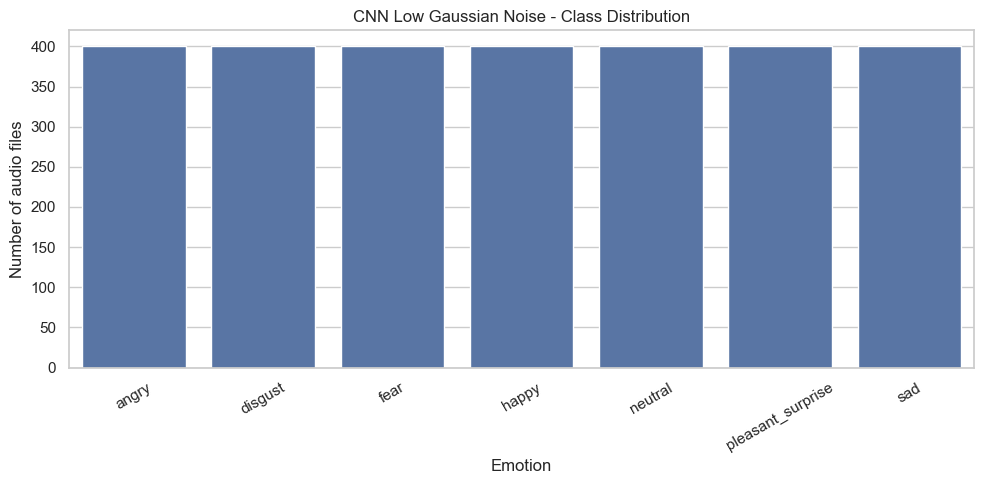

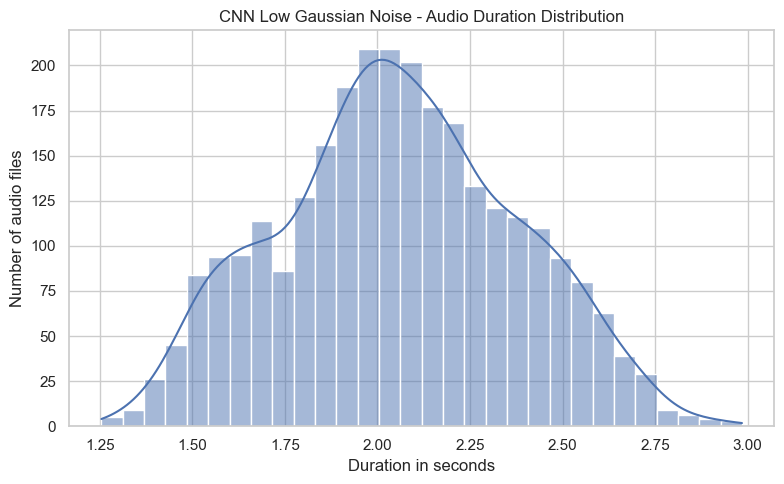

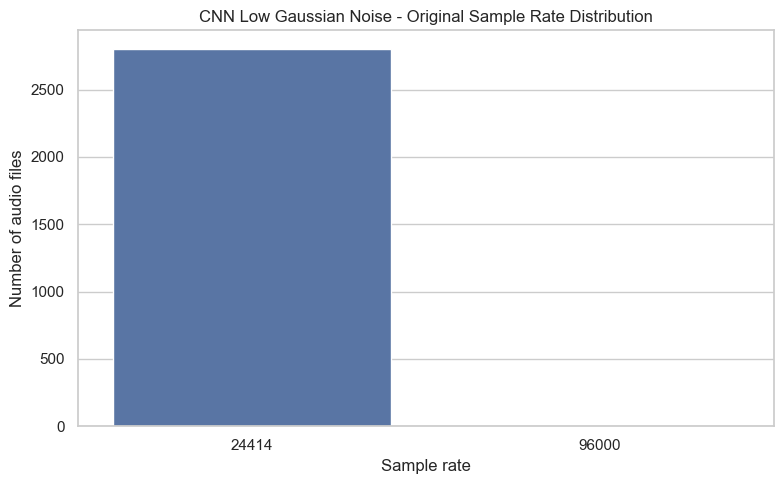

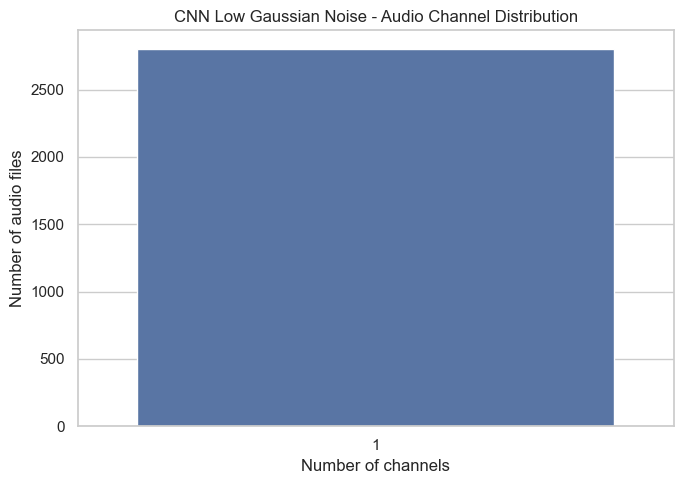

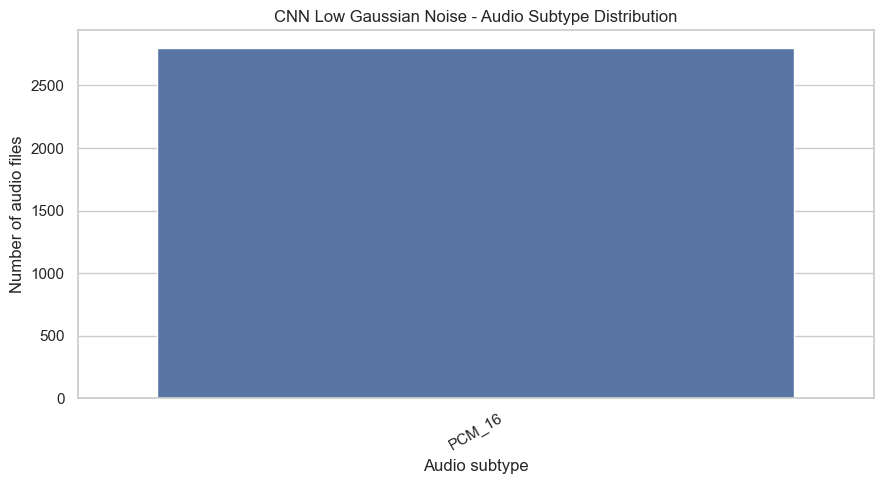

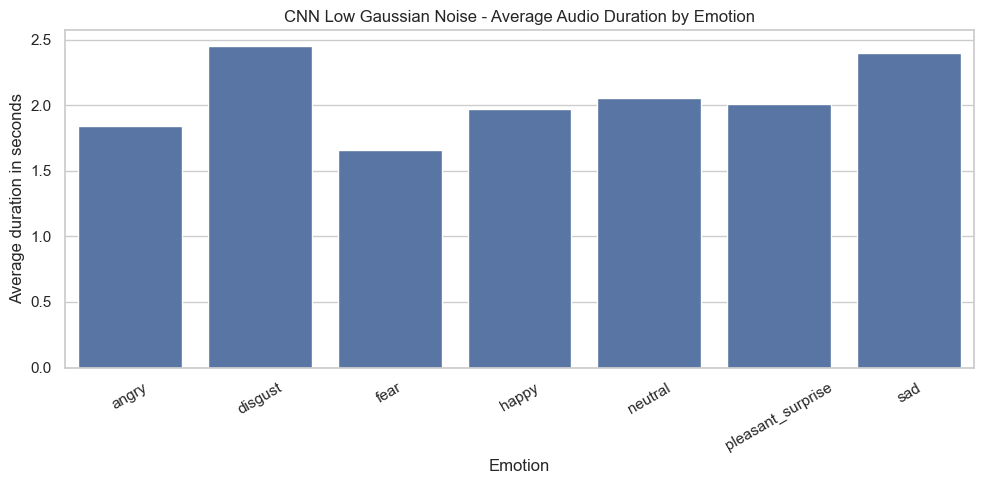

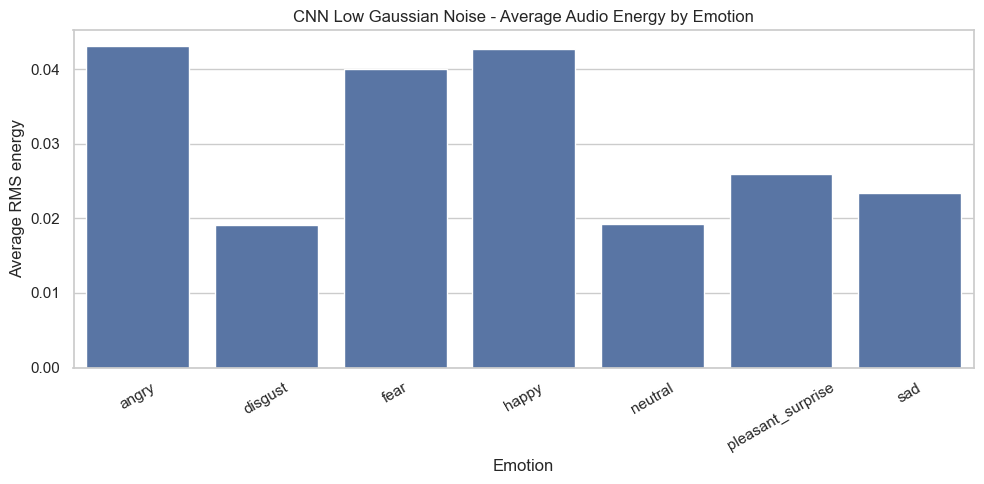

In [ ]:
# Plot how many files we have for each emotion.
plt.figure(figsize=(10, 5))
sns.countplot(data=metadata_df, x="emotion", order=sorted(metadata_df["emotion"].unique()))
plt.title(f"{MODEL_DISPLAY_NAME} - Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of audio files")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=200)
plt.show()

# Plot how long the audio files are.
plt.figure(figsize=(8, 5))
sns.histplot(metadata_df["duration_seconds"], bins=30, kde=True)
plt.title(f"{MODEL_DISPLAY_NAME} - Audio Duration Distribution")
plt.xlabel("Duration in seconds")
plt.ylabel("Number of audio files")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "audio_duration_distribution.png", dpi=200)
plt.show()

# Plot sample-rate counts.
plt.figure(figsize=(8, 5))
sns.countplot(data=metadata_df, x="original_sample_rate", order=sorted(metadata_df["original_sample_rate"].unique()))
plt.title(f"{MODEL_DISPLAY_NAME} - Original Sample Rate Distribution")
plt.xlabel("Sample rate")
plt.ylabel("Number of audio files")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_rate_distribution.png", dpi=200)
plt.show()

# Plot channel counts. Most TESS files should usually be mono.
plt.figure(figsize=(7, 5))
sns.countplot(data=metadata_df, x="channels", order=sorted(metadata_df["channels"].unique()))
plt.title(f"{MODEL_DISPLAY_NAME} - Audio Channel Distribution")
plt.xlabel("Number of channels")
plt.ylabel("Number of audio files")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "channel_distribution.png", dpi=200)
plt.show()

# Plot audio subtype counts, such as PCM_16.
plt.figure(figsize=(9, 5))
sns.countplot(data=metadata_df, x="audio_subtype", order=metadata_df["audio_subtype"].value_counts().index)
plt.title(f"{MODEL_DISPLAY_NAME} - Audio Subtype Distribution")
plt.xlabel("Audio subtype")
plt.ylabel("Number of audio files")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "audio_subtype_distribution.png", dpi=200)
plt.show()

# Plot average duration by emotion.
plt.figure(figsize=(10, 5))
sns.barplot(data=metadata_df, x="emotion", y="duration_seconds", estimator=np.mean, errorbar=None)
plt.title(f"{MODEL_DISPLAY_NAME} - Average Audio Duration by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average duration in seconds")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "duration_by_emotion.png", dpi=200)
plt.show()

# Plot average RMS energy by emotion.
plt.figure(figsize=(10, 5))
sns.barplot(data=metadata_df, x="emotion", y="rms_energy_mean", estimator=np.mean, errorbar=None)
plt.title(f"{MODEL_DISPLAY_NAME} - Average Audio Energy by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Average RMS energy")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "energy_by_emotion.png", dpi=200)
plt.show()

## 5. Audio Preprocessing




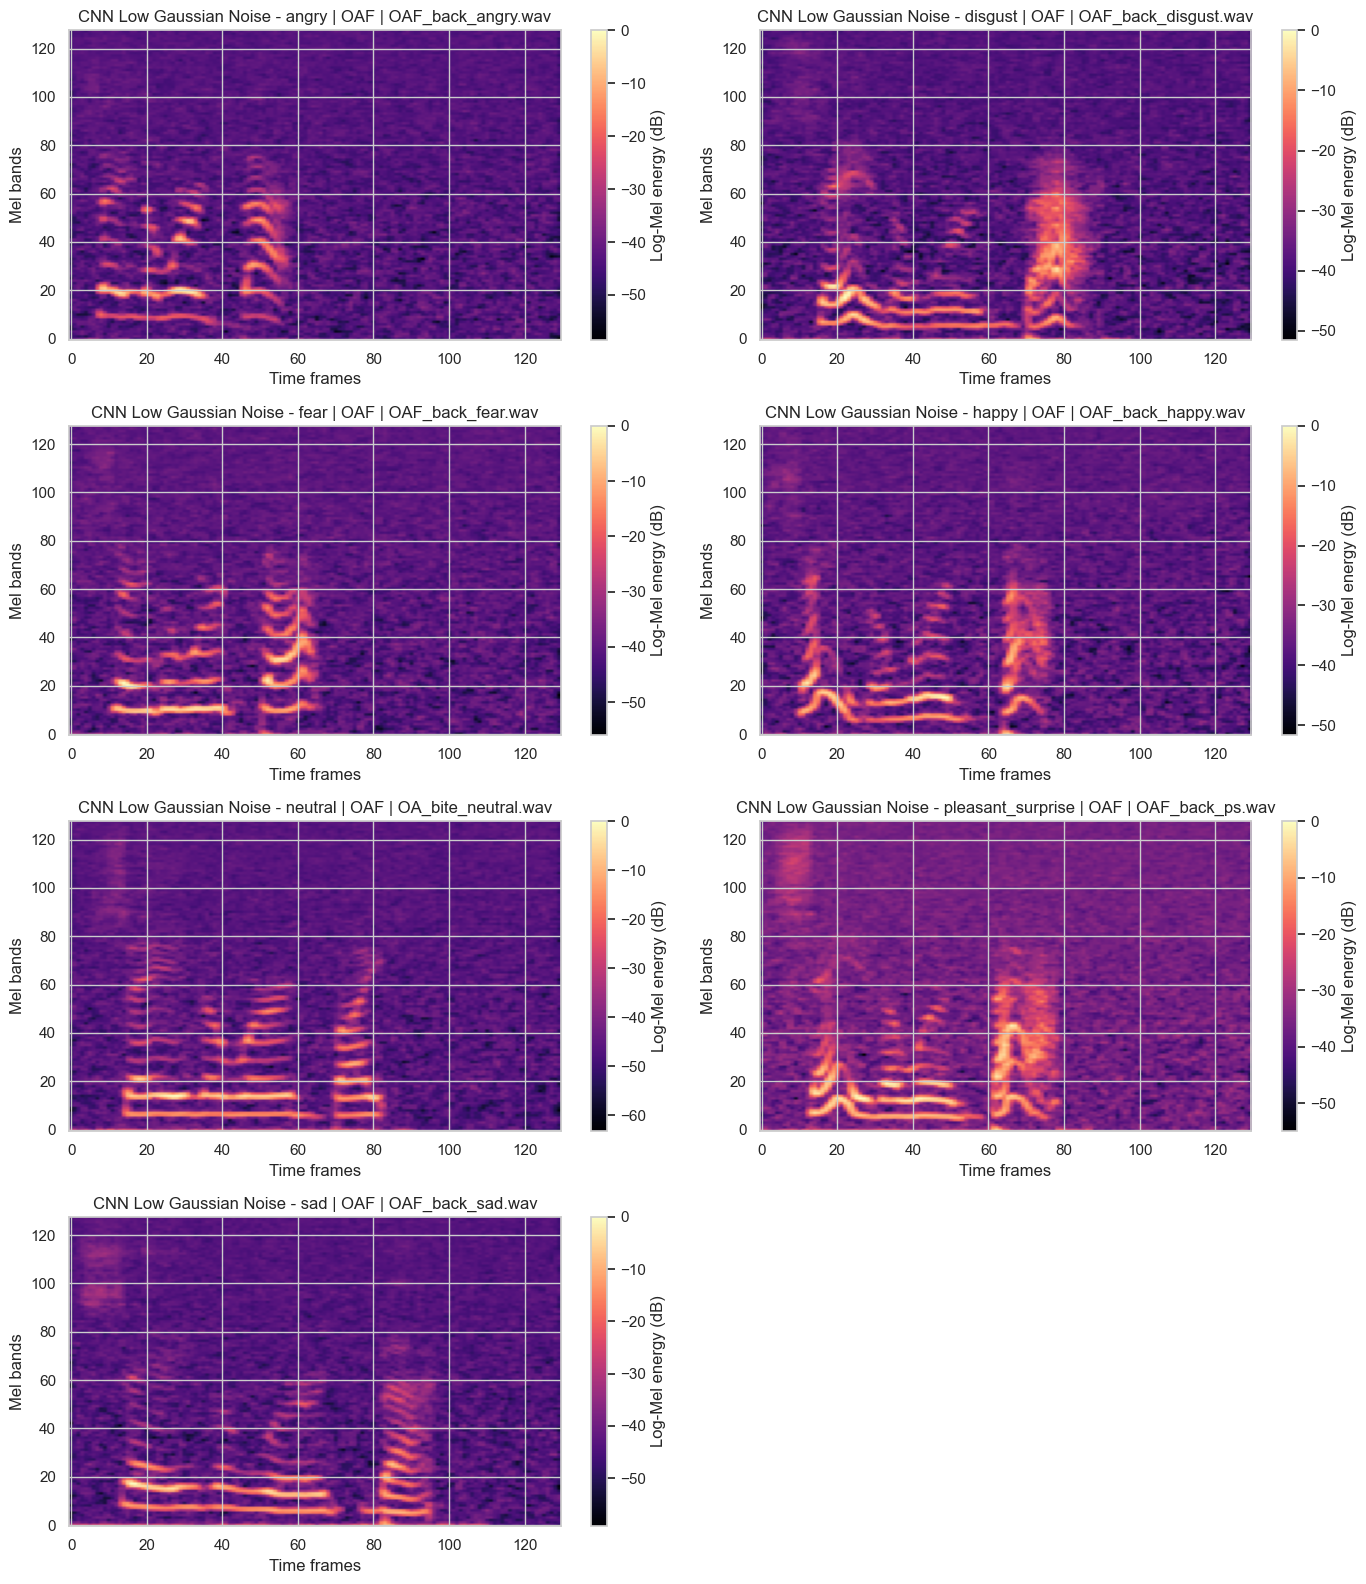

Model input spectrogram shape: (128, 130, 1)
Visualization dB spectrogram shape: (128, 130)
Saved plot to: outputs\cnn_low_gaussian_noise\spectrogram_examples_by_emotion.png


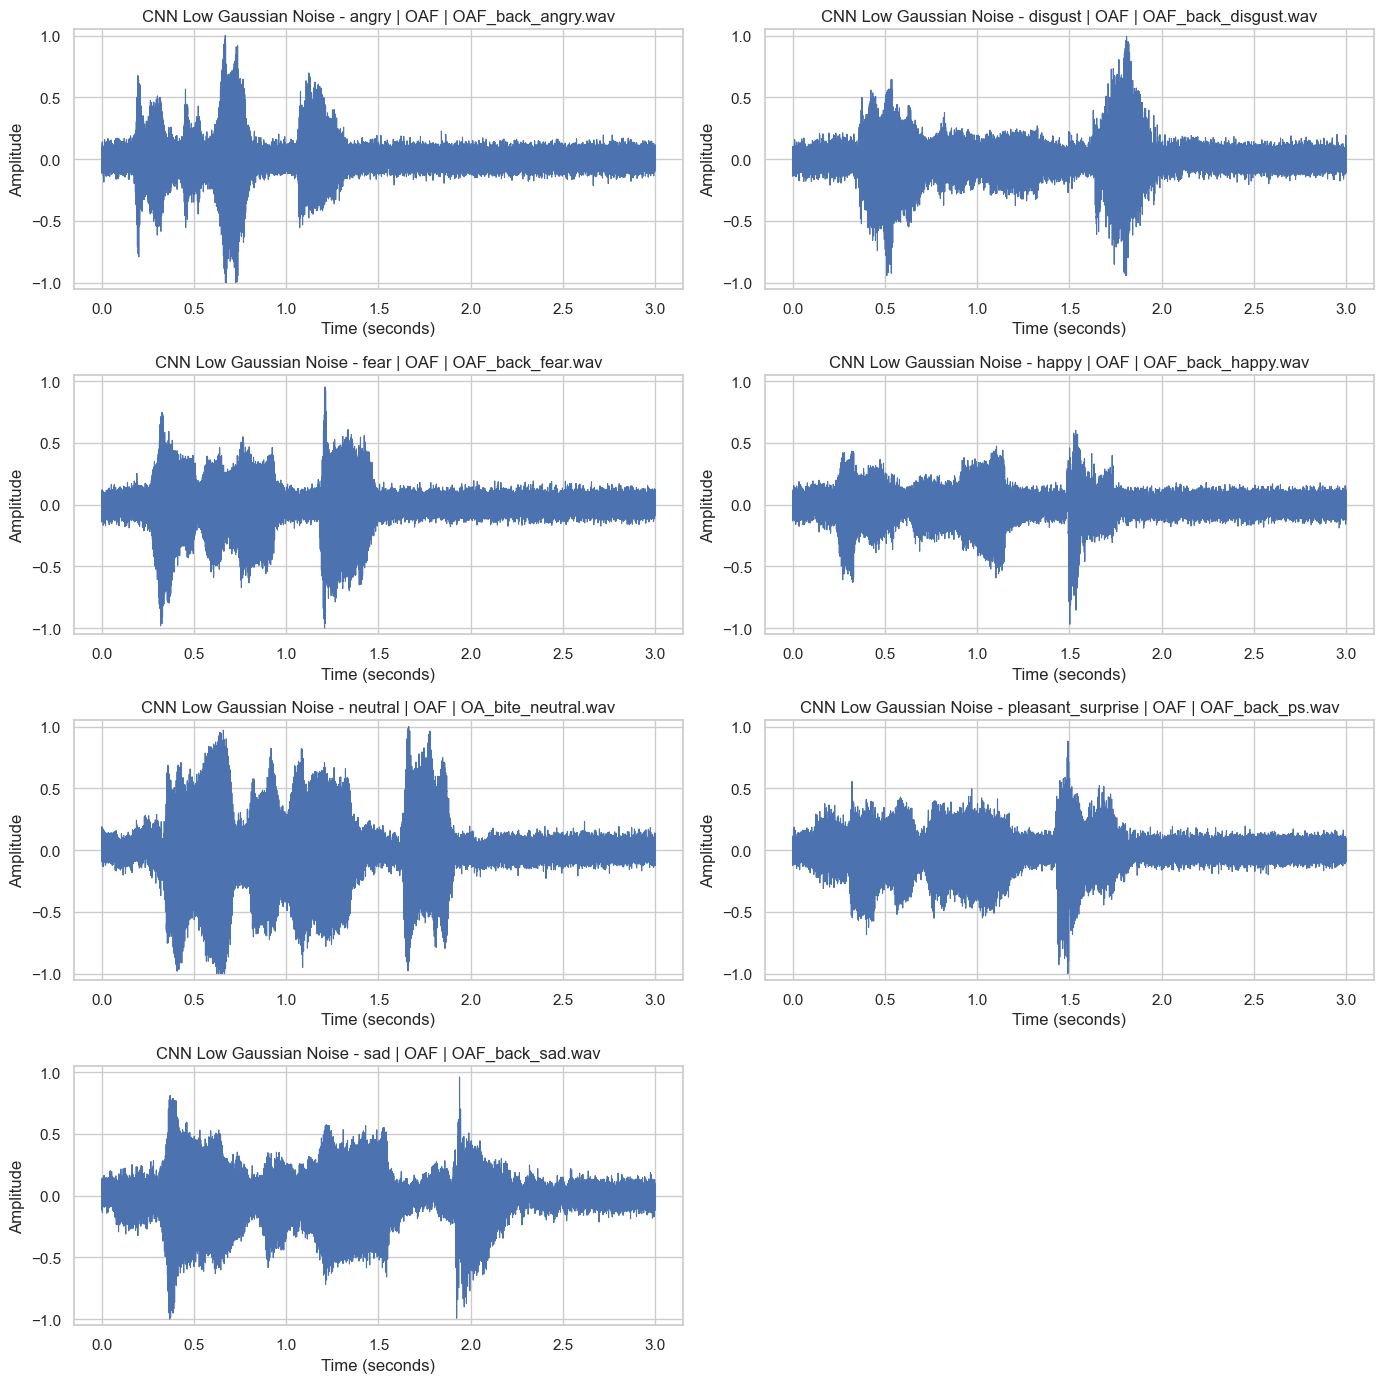

Saved plot to: outputs\cnn_low_gaussian_noise\waveform_examples_by_emotion.png


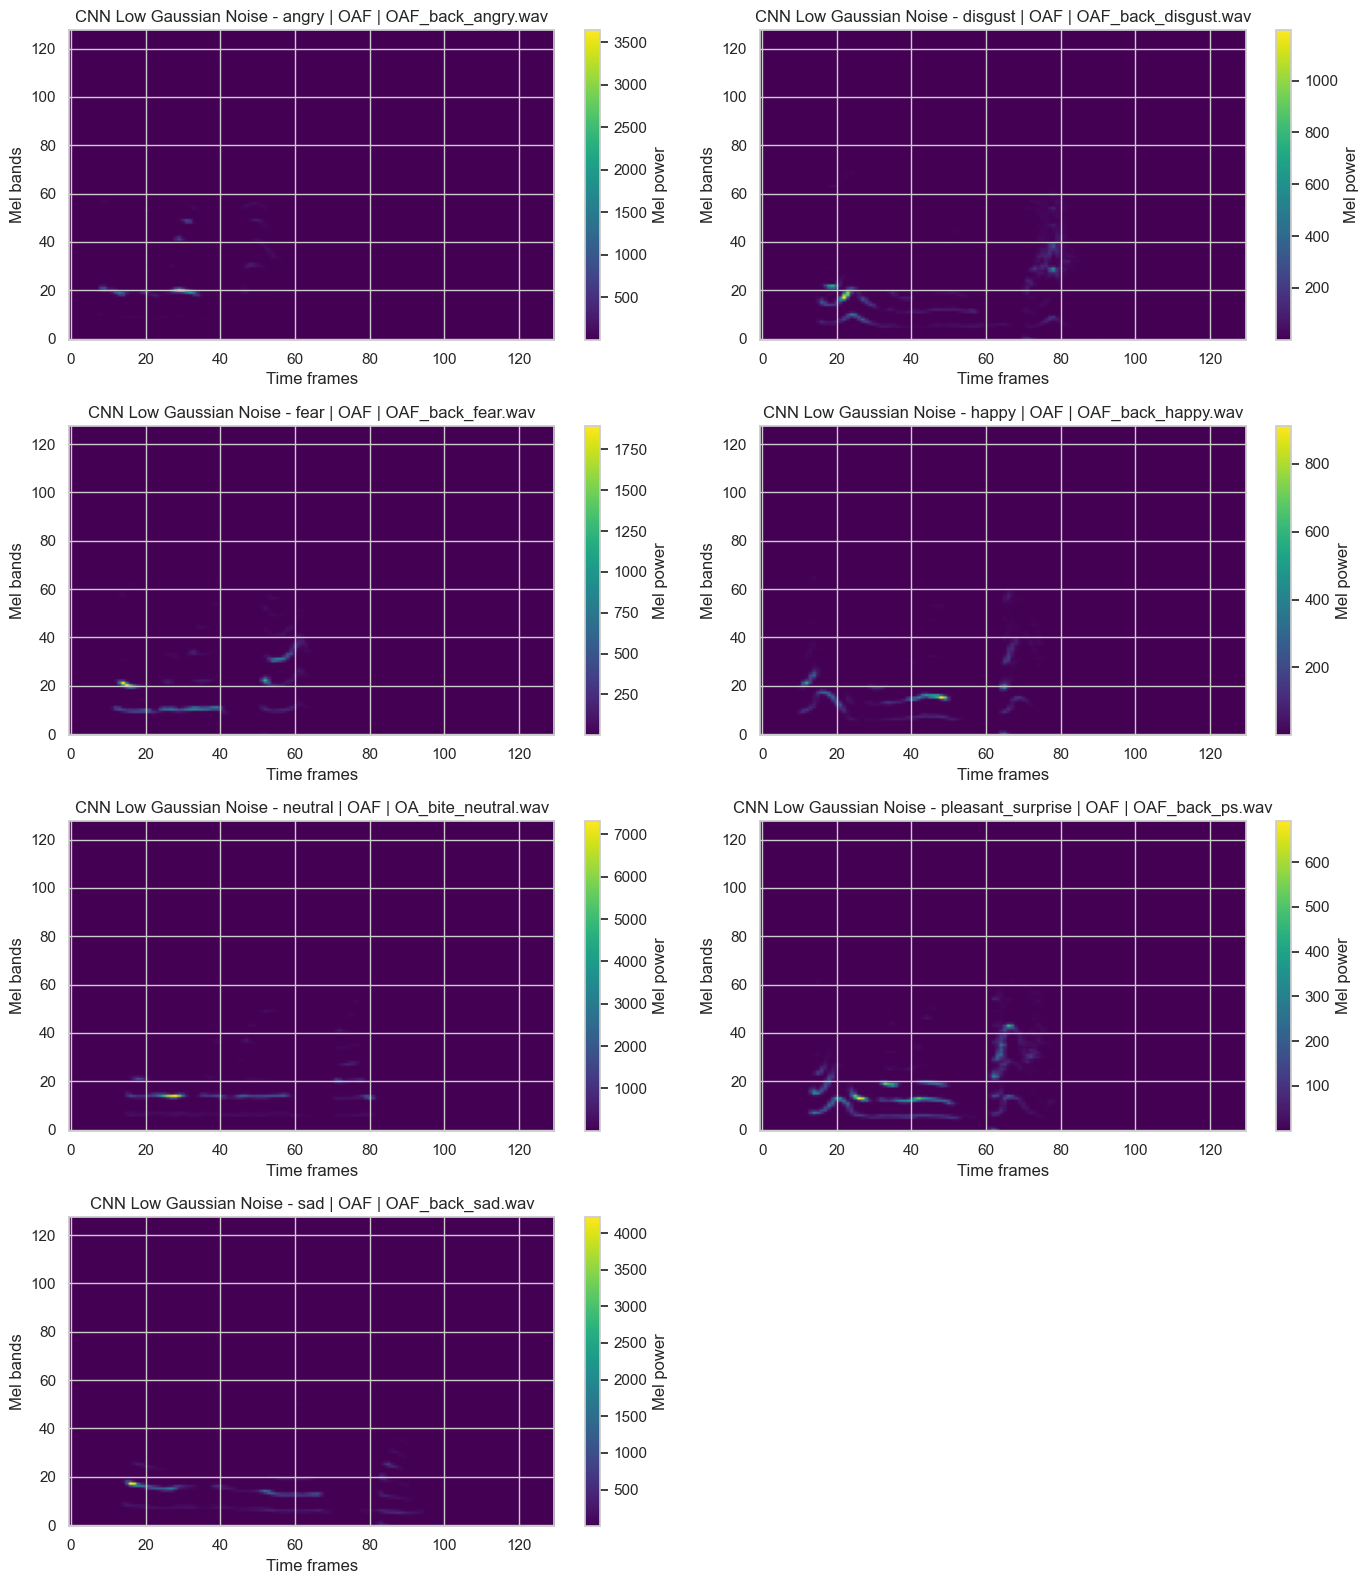

Saved plot to: outputs\cnn_low_gaussian_noise\mel_spectrogram_examples_by_emotion.png


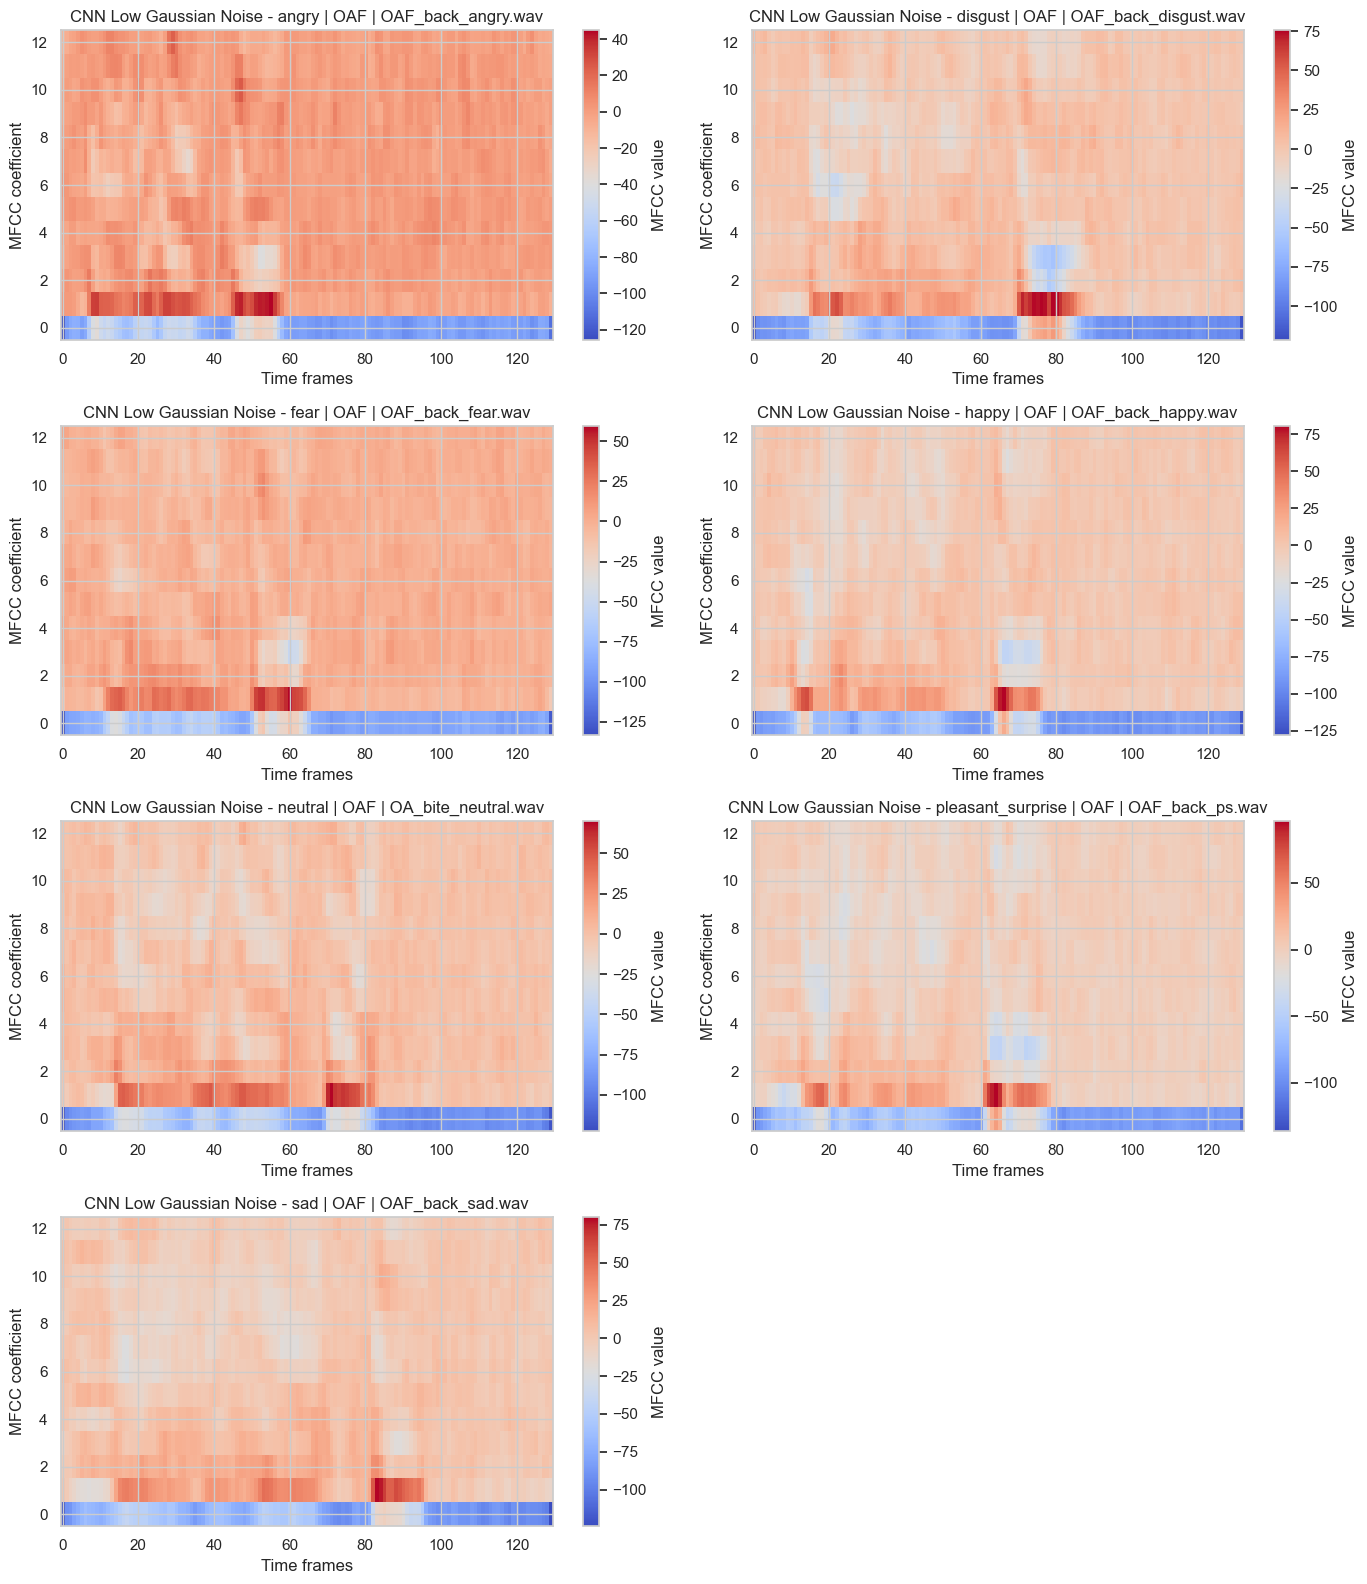

Saved plot to: outputs\cnn_low_gaussian_noise\mfcc_examples_by_emotion.png
Saved audio signal and spectrogram plot to: outputs\cnn_low_gaussian_noise\audio_signal_mel_logmel_mfcc_example.png


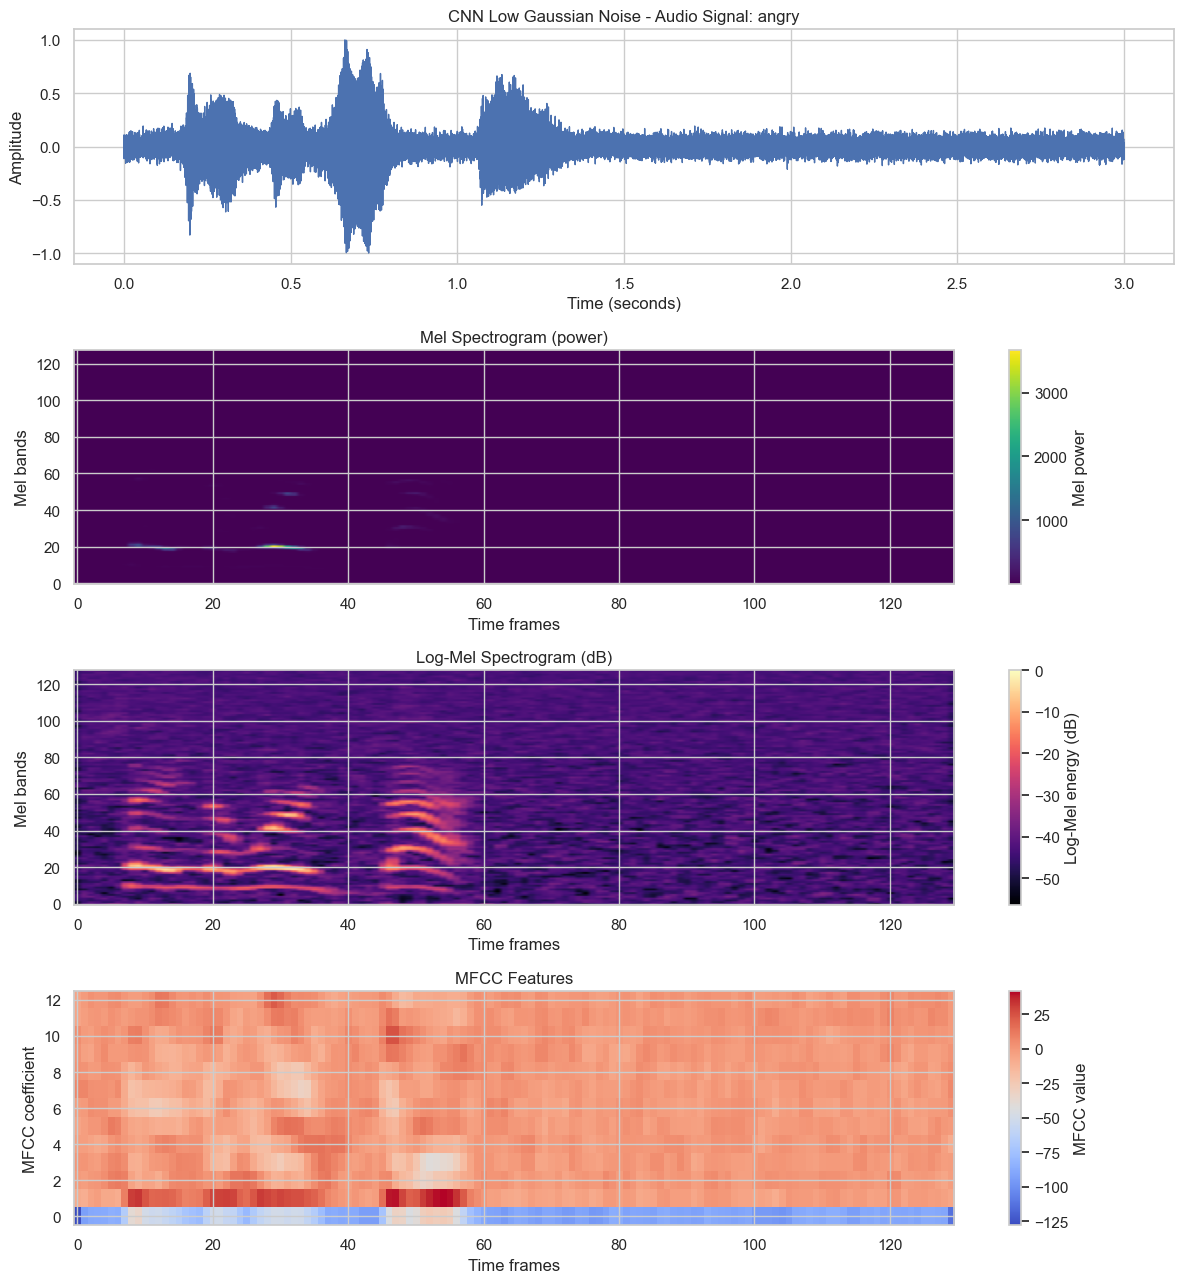

In [ ]:
def add_low_gaussian_noise(audio, noise_std=GAUSSIAN_NOISE_STD):
    # Gaussian noise is random small sound added to the audio.
    # A low value like 0.005 keeps the audio mostly clean but slightly harder.
    noise = np.random.normal(loc=0.0, scale=noise_std, size=audio.shape)
    noisy_audio = audio + noise

    # Keep the waveform inside the normal audio range.
    noisy_audio = np.clip(noisy_audio, -1.0, 1.0)
    return noisy_audio.astype(np.float32)


def load_audio_file(file_path, sample_rate=SAMPLE_RATE, duration_seconds=DURATION_SECONDS):
    # Load one audio file and make it ready for spectrogram creation.
    # librosa loads the audio as mono when mono=True.
    audio, sr = librosa.load(file_path, sr=sample_rate, mono=True)

    # We make every audio file the same length so the model gets the same size input each time.
    target_length = int(sample_rate * duration_seconds)

    if len(audio) < target_length:
        # If the audio is too short, we add silence at the end.
        audio = np.pad(audio, (0, target_length - len(audio)))
    else:
        # If the audio is too long, we keep only the first part.
        audio = audio[:target_length]

    # We normalize volume so loud and quiet files are easier to compare.
    max_value = np.max(np.abs(audio))
    if max_value > 0:
        audio = audio / max_value

    if ADD_GAUSSIAN_NOISE:
        # This is the main difference in this notebook:
        # every audio file receives low Gaussian noise before making the spectrogram.
        audio = add_low_gaussian_noise(audio)

    return audio


def create_spectrogram(file_path, sample_rate=SAMPLE_RATE, duration_seconds=DURATION_SECONDS, n_mels=N_MELS, return_db=False):
    # Turn one audio file into a log-mel spectrogram image.
    audio = load_audio_file(file_path, sample_rate, duration_seconds)

    # Mel spectrogram is like a picture showing where sound energy appears over time.
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_mels=n_mels,
        n_fft=2048,
        hop_length=512,
    )

    # Convert to decibels so the numbers are easier for the model to learn.
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Scale values to a simple 0 to 1 range.
    mel_min = mel_db.min()
    mel_max = mel_db.max()
    mel_scaled = (mel_db - mel_min) / (mel_max - mel_min + 1e-8)

    if return_db:
        # Use this for plots when you want to see the real decibel values.
        return mel_db.astype(np.float32)

    # CNN expects a channel dimension, like an image with one color channel.
    return mel_scaled[..., np.newaxis].astype(np.float32)


def create_spectrogram_db(file_path, sample_rate=SAMPLE_RATE, duration_seconds=DURATION_SECONDS, n_mels=N_MELS):
    # This helper is only for visualization.
    # It shows the log-Mel spectrogram in decibels before 0-to-1 scaling.
    return create_spectrogram(
        file_path,
        sample_rate=sample_rate,
        duration_seconds=duration_seconds,
        n_mels=n_mels,
        return_db=True,
    )


def create_mel_spectrogram(file_path, sample_rate=SAMPLE_RATE, duration_seconds=DURATION_SECONDS, n_mels=N_MELS):
    # This helper is only for visualization.
    # It returns the Mel spectrogram before converting it to decibels.
    audio = load_audio_file(file_path, sample_rate, duration_seconds)

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_mels=n_mels,
        n_fft=2048,
        hop_length=512,
    )

    return mel.astype(np.float32)


def create_mfcc_features(file_path, sample_rate=SAMPLE_RATE, duration_seconds=DURATION_SECONDS, n_mfcc=13):
    # This helper is only for visualization and analysis.
    # MFCCs are compact audio features that summarize the shape of the sound spectrum.
    audio = load_audio_file(file_path, sample_rate, duration_seconds)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=n_mfcc,
        n_fft=2048,
        hop_length=512,
    )

    return mfcc.astype(np.float32)


def show_mfcc_examples_by_emotion(df):
    # Show one MFCC example for each emotion type.
    emotions = sorted(df["emotion"].unique())
    columns = 2
    rows = int(np.ceil(len(emotions) / columns))

    plt.figure(figsize=(14, rows * 4))

    for index, emotion in enumerate(emotions, start=1):
        example_row = df[df["emotion"] == emotion].iloc[0]
        example_mfcc = create_mfcc_features(example_row["file_path"])

        plt.subplot(rows, columns, index)
        img = plt.imshow(example_mfcc, aspect="auto", origin="lower", cmap="coolwarm")
        plt.title(f"{MODEL_DISPLAY_NAME} - {emotion} | {example_row['speaker']} | {example_row['file_name']}")
        plt.xlabel("Time frames")
        plt.ylabel("MFCC coefficient")
        plt.colorbar(img, label="MFCC value")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "mfcc_examples_by_emotion.png", dpi=200)
    plt.show()

    print("Saved plot to:", OUTPUT_DIR / "mfcc_examples_by_emotion.png")


def plot_audio_signal_and_spectrograms(file_path, emotion_name="example", save_path=None):
    # This plot helps us see how one audio file changes from sound to model feature.
    # Row 1: the audio waveform.
    # Row 2: the Mel spectrogram before dB conversion.
    # Row 3: the log-Mel spectrogram in decibels.
    # Row 4: MFCC features for classical audio analysis.
    audio = load_audio_file(file_path)
    mel = create_mel_spectrogram(file_path)
    mel_db = create_spectrogram_db(file_path)
    mfcc = create_mfcc_features(file_path)

    time_axis = np.linspace(0, len(audio) / SAMPLE_RATE, num=len(audio))

    plt.figure(figsize=(12, 13))

    plt.subplot(4, 1, 1)
    plt.plot(time_axis, audio, linewidth=1)
    plt.title(f"{MODEL_DISPLAY_NAME} - Audio Signal: {emotion_name}")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")

    plt.subplot(4, 1, 2)
    mel_image = plt.imshow(mel, aspect="auto", origin="lower", cmap="viridis")
    plt.title("Mel Spectrogram (power)")
    plt.xlabel("Time frames")
    plt.ylabel("Mel bands")
    plt.colorbar(mel_image, label="Mel power")

    plt.subplot(4, 1, 3)
    log_mel_image = plt.imshow(mel_db, aspect="auto", origin="lower", cmap="magma")
    plt.title("Log-Mel Spectrogram (dB)")
    plt.xlabel("Time frames")
    plt.ylabel("Mel bands")
    plt.colorbar(log_mel_image, label="Log-Mel energy (dB)")

    plt.subplot(4, 1, 4)
    mfcc_image = plt.imshow(mfcc, aspect="auto", origin="lower", cmap="coolwarm")
    plt.title("MFCC Features")
    plt.xlabel("Time frames")
    plt.ylabel("MFCC coefficient")
    plt.colorbar(mfcc_image, label="MFCC value")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200)
        print("Saved audio signal and spectrogram plot to:", save_path)

    plt.show()


def show_waveform_examples_by_emotion(df):
    # Show one audio waveform example for each emotion type.
    # A waveform is the raw audio signal: time on the x-axis and amplitude on the y-axis.
    emotions = sorted(df["emotion"].unique())
    columns = 2
    rows = int(np.ceil(len(emotions) / columns))

    plt.figure(figsize=(14, rows * 3.5))

    for index, emotion in enumerate(emotions, start=1):
        example_row = df[df["emotion"] == emotion].iloc[0]
        audio = load_audio_file(example_row["file_path"])
        time_axis = np.linspace(0, len(audio) / SAMPLE_RATE, num=len(audio))

        plt.subplot(rows, columns, index)
        plt.plot(time_axis, audio, linewidth=0.8)
        plt.title(f"{MODEL_DISPLAY_NAME} - {emotion} | {example_row['speaker']} | {example_row['file_name']}")
        plt.xlabel("Time (seconds)")
        plt.ylabel("Amplitude")
        plt.ylim(-1.05, 1.05)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "waveform_examples_by_emotion.png", dpi=200)
    plt.show()

    print("Saved plot to:", OUTPUT_DIR / "waveform_examples_by_emotion.png")


def show_mel_spectrogram_examples_by_emotion(df):
    # Show one Mel spectrogram example for each emotion type.
    # This is different from the log-Mel dB plot because these values are still power values.
    emotions = sorted(df["emotion"].unique())
    columns = 2
    rows = int(np.ceil(len(emotions) / columns))

    plt.figure(figsize=(14, rows * 4))

    for index, emotion in enumerate(emotions, start=1):
        example_row = df[df["emotion"] == emotion].iloc[0]
        example_mel = create_mel_spectrogram(example_row["file_path"])

        plt.subplot(rows, columns, index)
        img = plt.imshow(example_mel, aspect="auto", origin="lower", cmap="viridis")
        plt.title(f"{MODEL_DISPLAY_NAME} - {emotion} | {example_row['speaker']} | {example_row['file_name']}")
        plt.xlabel("Time frames")
        plt.ylabel("Mel bands")
        plt.colorbar(img, label="Mel power")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "mel_spectrogram_examples_by_emotion.png", dpi=200)
    plt.show()

    print("Saved plot to:", OUTPUT_DIR / "mel_spectrogram_examples_by_emotion.png")


def show_spectrogram_examples_by_emotion(df):
    # Show one example spectrogram for each emotion type.
    emotions = sorted(df["emotion"].unique())
    columns = 2
    rows = int(np.ceil(len(emotions) / columns))

    plt.figure(figsize=(14, rows * 4))

    for index, emotion in enumerate(emotions, start=1):
        # Pick the first audio file for this emotion.
        example_row = df[df["emotion"] == emotion].iloc[0]
        example_spec_db = create_spectrogram_db(example_row["file_path"])

        plt.subplot(rows, columns, index)
        img = plt.imshow(example_spec_db, aspect="auto", origin="lower", cmap="magma")
        plt.title(f"{MODEL_DISPLAY_NAME} - {emotion} | {example_row['speaker']} | {example_row['file_name']}")
        plt.xlabel("Time frames")
        plt.ylabel("Mel bands")
        plt.colorbar(img, label="Log-Mel energy (dB)")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "spectrogram_examples_by_emotion.png", dpi=200)
    plt.show()

    print("Model input spectrogram shape:", create_spectrogram(df.iloc[0]["file_path"]).shape)
    print("Visualization dB spectrogram shape:", create_spectrogram_db(df.iloc[0]["file_path"]).shape)
    print("Saved plot to:", OUTPUT_DIR / "spectrogram_examples_by_emotion.png")


show_spectrogram_examples_by_emotion(metadata_df)


show_waveform_examples_by_emotion(metadata_df)
show_mel_spectrogram_examples_by_emotion(metadata_df)
show_mfcc_examples_by_emotion(metadata_df)

example_row = metadata_df.iloc[0]
plot_audio_signal_and_spectrograms(
    example_row["file_path"],
    emotion_name=example_row["emotion"],
    save_path=OUTPUT_DIR / "audio_signal_mel_logmel_mfcc_example.png",
)


## 6. Create or Load Cached Features




In [ ]:
def build_feature_cache(df, cache_path=FEATURE_CACHE_PATH):
    # Create spectrograms for all files, or load them if they already exist.
    if cache_path.exists():
        print("Loading cached features from:", cache_path)
        cache = np.load(cache_path, allow_pickle=True)
        X = cache["X"]
        labels = cache["labels"]
        file_paths = cache["file_paths"]
        return X, labels, file_paths

    print("Creating spectrogram features. This may take a few minutes...")
    X_list = []
    labels = []
    file_paths = []

    for index, row in df.iterrows():
        spec = create_spectrogram(row["file_path"])
        X_list.append(spec)
        labels.append(row["emotion"])
        file_paths.append(row["file_path"])

        if (index + 1) % 200 == 0:
            print(f"Processed {index + 1}/{len(df)} files")

    X = np.array(X_list, dtype=np.float32)
    labels = np.array(labels)
    file_paths = np.array(file_paths)

    np.savez_compressed(cache_path, X=X, labels=labels, file_paths=file_paths)
    print("Saved cached features to:", cache_path)
    return X, labels, file_paths


X, labels, feature_file_paths = build_feature_cache(metadata_df)

print("Feature tensor shape:", X.shape)
print("Labels shape:", labels.shape)

Loading cached features from: outputs\cnn_low_gaussian_noise\features_cache_low_gaussian_noise.npz
Feature tensor shape: (2800, 128, 130, 1)
Labels shape: (2800,)


## 7. Encode Labels and Split the Data




In [ ]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)
class_names = list(label_encoder.classes_)

with open(LABEL_ENCODER_PATH, "wb") as f:
    pickle.dump(label_encoder, f)

print("Classes:")
for number, name in enumerate(class_names):
    print(number, "=", name)

# First, separate the final test set.
X_train_val, X_test, y_train_val, y_test, paths_train_val, paths_test = train_test_split(
    X,
    y,
    feature_file_paths,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Now split the remaining data into train and validation.
# This formula makes validation 15% of the full dataset.
validation_fraction_of_train_val = VALIDATION_SIZE / (1.0 - TEST_SIZE)

X_train, X_val, y_train, y_val, paths_train, paths_val = train_test_split(
    X_train_val,
    y_train_val,
    paths_train_val,
    test_size=validation_fraction_of_train_val,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Classes:
0 = angry
1 = disgust
2 = fear
3 = happy
4 = neutral
5 = pleasant_surprise
6 = sad
Train shape: (1960, 128, 130, 1)
Validation shape: (420, 128, 130, 1)
Test shape: (420, 128, 130, 1)


## 8. Build the CNN Model






In [ ]:
def build_cnn_model(input_shape, num_classes, learning_rate=0.001, dropout_rate=0.35, cnn_size="medium"):
    # Build a simple CNN model for emotion classification.
    if cnn_size == "small":
        filters = [16, 32, 64]
        dense_units = 64
    else:
        filters = [32, 64, 128]
        dense_units = 128

    model = keras.Sequential(name=f"tess_cnn_{cnn_size}")

    # Input layer tells the model the shape of one spectrogram.
    model.add(layers.Input(shape=input_shape))

    # First CNN block learns simple sound-picture patterns.
    model.add(layers.Conv2D(filters[0], (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    # Second CNN block learns bigger patterns.
    model.add(layers.Conv2D(filters[1], (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    # Third CNN block learns more detailed emotion patterns.
    model.add(layers.Conv2D(filters[2], (3, 3), activation="relu", padding="same"))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(dropout_rate))

    # Flatten changes the 2D picture features into one long list of numbers.
    model.add(layers.Flatten())

    # This layer is named "embedding" so we can use it later for t-SNE.
    model.add(layers.Dense(dense_units, activation="relu", name="embedding"))
    model.add(layers.Dropout(dropout_rate))

    # Softmax gives one probability for each emotion.
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


input_shape = X_train.shape[1:]
num_classes = len(class_names)

preview_model = build_cnn_model(input_shape, num_classes)
preview_model.summary()

Model: "tess_cnn_medium"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 130, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 130, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,903 (16.36 MB)

 Trainable params: 4,288,455 (16.36 MB)

 Non-trainable params: 448 (1.75 KB)

## 9. Training and Plotting Functions



In [ ]:
def plot_training_history(history_df, save_path=OUTPUT_DIR / "training_curves.png"):
    # Plot loss and accuracy for training and validation.
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history_df["loss"], label="Train loss")
    plt.plot(history_df["val_loss"], label="Validation loss")
    plt.title(f"{MODEL_DISPLAY_NAME} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_df["accuracy"], label="Train accuracy")
    plt.plot(history_df["val_accuracy"], label="Validation accuracy")
    plt.title(f"{MODEL_DISPLAY_NAME} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()


def train_model(
    run_name,
    learning_rate=0.001,
    dropout_rate=0.35,
    batch_size=32,
    cnn_size="medium",
    epochs=EPOCHS,
):
    # Train one CNN model and save the best checkpoint.
    run_dir = MODEL_RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    model_path = run_dir / "best_model.keras"
    history_path = run_dir / "training_history.csv"

    model = build_cnn_model(
        input_shape=input_shape,
        num_classes=num_classes,
        learning_rate=learning_rate,
        dropout_rate=dropout_rate,
        cnn_size=cnn_size,
    )

    callbacks = [
        # Save the model that does best on validation accuracy.
        keras.callbacks.ModelCheckpoint(
            model_path,
            monitor="val_accuracy",
            save_best_only=True,
            mode="max",
            verbose=1,
        ),
        # Stop training if validation loss stops improving.
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1,
        ),
    ]

    start_time = time.time()
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1,
    )
    training_minutes = (time.time() - start_time) / 60

    history_df = pd.DataFrame(history.history)
    history_df.to_csv(history_path, index=False)

    best_val_accuracy = float(history_df["val_accuracy"].max())
    best_val_loss = float(history_df["val_loss"].min())

    return {
        "run_name": run_name,
        "model_path": str(model_path),
        "history_path": str(history_path),
        "learning_rate": learning_rate,
        "dropout_rate": dropout_rate,
        "batch_size": batch_size,
        "cnn_size": cnn_size,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
        "training_minutes": training_minutes,
    }

## 10. Fine Tuning




In [ ]:
# Set this lower if you want a quick first run.
# Set MAX_TUNING_TRIALS = None to run the full grid.
MAX_TUNING_TRIALS = 4

tuning_grid = []
for learning_rate in [0.001, 0.0005]:
    for dropout_rate in [0.25, 0.35]:
        for batch_size in [16, 32]:
            for cnn_size in ["small", "medium"]:
                tuning_grid.append({
                    "learning_rate": learning_rate,
                    "dropout_rate": dropout_rate,
                    "batch_size": batch_size,
                    "cnn_size": cnn_size,
                })

if MAX_TUNING_TRIALS is not None:
    tuning_grid = tuning_grid[:MAX_TUNING_TRIALS]

print("Number of tuning trials:", len(tuning_grid))
pd.DataFrame(tuning_grid)

Number of tuning trials: 4


,learning_rate,dropout_rate,batch_size,cnn_size
0,0.001,0.25,16,small
1,0.001,0.25,16,medium
2,0.001,0.25,32,small
3,0.001,0.25,32,medium


In [ ]:
tuning_results = []

for trial_number, params in enumerate(tuning_grid, start=1):
    run_name = f"trial_{trial_number:02d}_lr{params['learning_rate']}_do{params['dropout_rate']}_bs{params['batch_size']}_{params['cnn_size']}"
    print("\n" + "=" * 80)
    print("Starting", run_name)
    print(params)
    print("=" * 80)

    result = train_model(run_name=run_name, **params)
    tuning_results.append(result)

tuning_results_df = pd.DataFrame(tuning_results).sort_values("best_val_accuracy", ascending=False)
tuning_results_df.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)
tuning_results_df


Starting trial_01_lr0.001_do0.25_bs16_small
{'learning_rate': 0.001, 'dropout_rate': 0.25, 'batch_size': 16, 'cnn_size': 'small'}
Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4311 - loss: 2.5908
Epoch 1: val_accuracy improved from None to 0.14286, saving model to outputs\cnn_low_gaussian_noise\model_runs\trial_01_lr0.001_do0.25_bs16_small\best_model.keras

Epoch 1: finished saving model to outputs\cnn_low_gaussian_noise\model_runs\trial_01_lr0.001_do0.25_bs16_small\best_model.keras
123/123 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.5571 - loss: 1.4997 - val_accuracy: 0.1429 - val_loss: 18.5780 - learning_rate: 0.0010
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.8219 - loss: 0.4987
Epoch 2: val_accuracy improved from 0.14286 to 0.22619, saving model to outputs\cnn_low_gaussian_noise\model_runs\trial_01_lr0.001_do0.25_bs16_small\best_model.keras

Epoch 2: finished saving model to outputs\cnn_low_gaussian_noise\model_runs\trial_01_lr0.001_

,run_name,model_path,history_path,learning_rate,dropout_rate,batch_size,cnn_size,best_val_accuracy,best_val_loss,training_minutes
0,trial_01_lr0.001_do0.25_bs16_small,outputs\cnn_low_gaussian_noise\model_runs\tria...,outputs\cnn_low_gaussian_noise\model_runs\tria...,0.001,0.25,16,small,1.0,0.000060,3.832335
1,trial_02_lr0.001_do0.25_bs16_medium,outputs\cnn_low_gaussian_noise\model_runs\tria...,outputs\cnn_low_gaussian_noise\model_runs\tria...,0.001,0.25,16,medium,1.0,0.000022,4.449259
2,trial_03_lr0.001_do0.25_bs32_small,outputs\cnn_low_gaussian_noise\model_runs\tria...,outputs\cnn_low_gaussian_noise\model_runs\tria...,0.001,0.25,32,small,1.0,0.000035,4.055676
3,trial_04_lr0.001_do0.25_bs32_medium,outputs\cnn_low_gaussian_noise\model_runs\tria...,outputs\cnn_low_gaussian_noise\model_runs\tria...,0.001,0.25,32,medium,1.0,0.000101,8.131709


## 11. Save the Best Model



Best model saved to: outputs\cnn_low_gaussian_noise\best_cnn_low_gaussian_noise_model.keras
Best settings:
run_name                            trial_01_lr0.001_do0.25_bs16_small
model_path           outputs\cnn_low_gaussian_noise\model_runs\tria...
history_path         outputs\cnn_low_gaussian_noise\model_runs\tria...
learning_rate                                                    0.001
dropout_rate                                                      0.25
batch_size                                                          16
cnn_size                                                         small
best_val_accuracy                                                  1.0
best_val_loss                                                  0.00006
training_minutes                                              3.832335
Name: 0, dtype: object


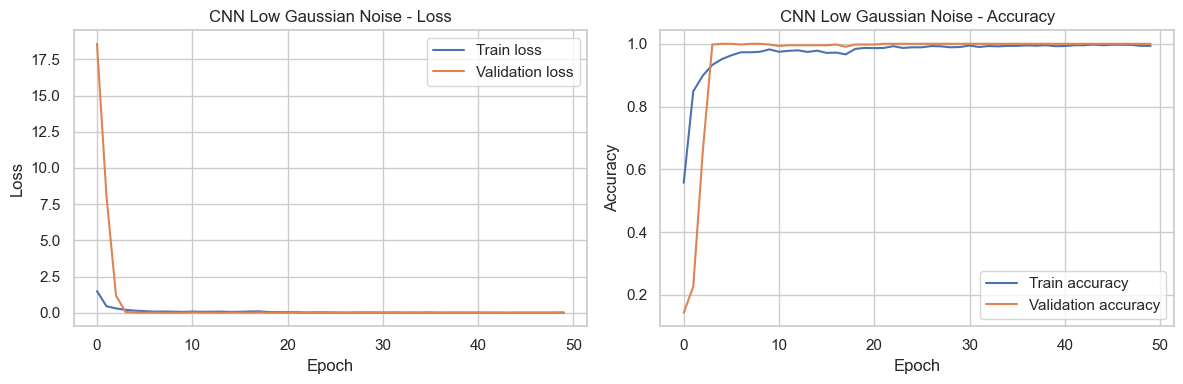

In [ ]:
best_row = tuning_results_df.iloc[0]
best_model_from_trial = Path(best_row["model_path"])

# Copy the best model to the main output path.
shutil.copy2(best_model_from_trial, BEST_MODEL_PATH)

# Also save the best model's training history as the main history file.
shutil.copy2(Path(best_row["history_path"]), OUTPUT_DIR / "training_history.csv")

best_model = keras.models.load_model(BEST_MODEL_PATH)
best_history_df = pd.read_csv(OUTPUT_DIR / "training_history.csv")

print("Best model saved to:", BEST_MODEL_PATH)
print("Best settings:")
print(best_row)

plot_training_history(best_history_df, OUTPUT_DIR / "training_curves.png")

## 12. Evaluation Metrics



Test accuracy: 1.0

Classification report:
                   precision    recall  f1-score   support

            angry     1.0000    1.0000    1.0000        60
          disgust     1.0000    1.0000    1.0000        60
             fear     1.0000    1.0000    1.0000        60
            happy     1.0000    1.0000    1.0000        60
          neutral     1.0000    1.0000    1.0000        60
pleasant_surprise     1.0000    1.0000    1.0000        60
              sad     1.0000    1.0000    1.0000        60

         accuracy                         1.0000       420
        macro avg     1.0000    1.0000    1.0000       420
     weighted avg     1.0000    1.0000    1.0000       420



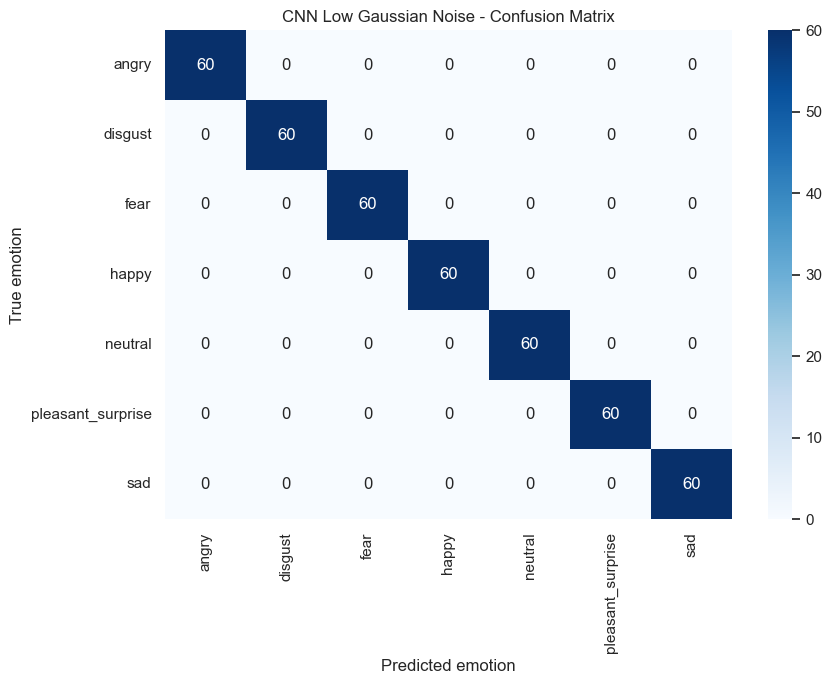


AUC report:


,emotion,auc
0,angry,1.0
1,disgust,1.0
2,fear,1.0
3,happy,1.0
4,neutral,1.0
5,pleasant_surprise,1.0
6,sad,1.0
7,macro_average,1.0
8,weighted_average,1.0


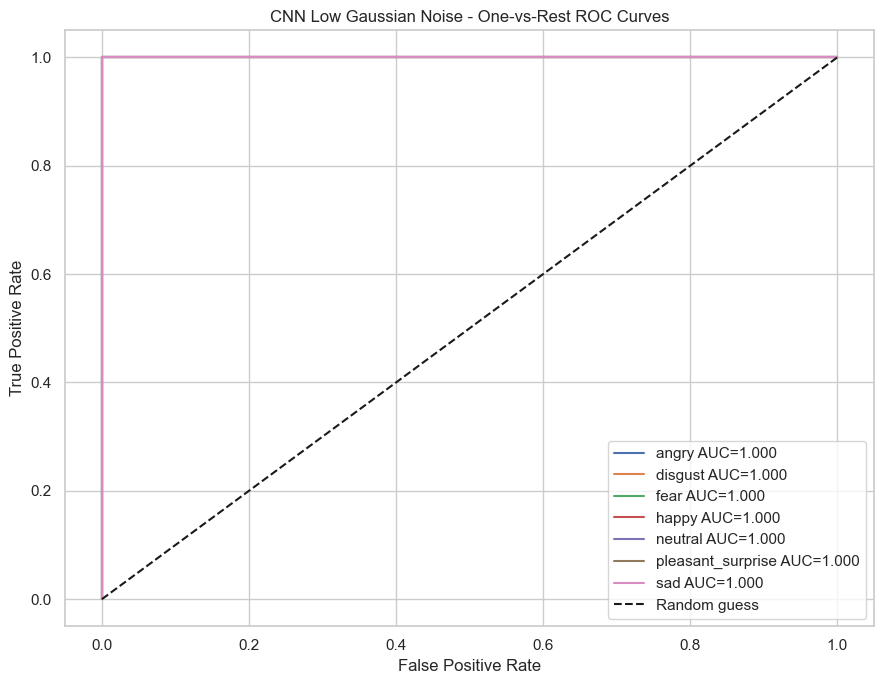

In [ ]:
def evaluate_model(model, X_test, y_test, class_names, paths_test):
    # Evaluate the model and save reports.
    y_prob = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    accuracy = accuracy_score(y_test, y_pred)
    report_text = classification_report(y_test, y_pred, target_names=class_names, digits=4)
    report_dict = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)

    print("Test accuracy:", accuracy)
    print("\nClassification report:")
    print(report_text)

    with open(OUTPUT_DIR / "classification_report.txt", "w", encoding="utf-8") as f:
        f.write(report_text)

    pd.DataFrame(report_dict).transpose().to_csv(OUTPUT_DIR / "test_metrics.csv")

    # Confusion matrix shows which emotions are confused with each other.
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"{MODEL_DISPLAY_NAME} - Confusion Matrix")
    plt.xlabel("Predicted emotion")
    plt.ylabel("True emotion")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=200)
    plt.show()

    # AUC needs probability scores, not just final labels.
    y_test_binary = label_binarize(y_test, classes=np.arange(len(class_names)))

    auc_rows = []
    for i, class_name in enumerate(class_names):
        auc_value = roc_auc_score(y_test_binary[:, i], y_prob[:, i])
        auc_rows.append({"emotion": class_name, "auc": auc_value})

    macro_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")
    weighted_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="weighted")
    auc_rows.append({"emotion": "macro_average", "auc": macro_auc})
    auc_rows.append({"emotion": "weighted_average", "auc": weighted_auc})

    auc_df = pd.DataFrame(auc_rows)
    auc_df.to_csv(OUTPUT_DIR / "auc_report.csv", index=False)

    print("\nAUC report:")
    display(auc_df)

    # ROC curves show how each class performs across many thresholds.
    plt.figure(figsize=(9, 7))
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=f"{class_name} AUC={auc_rows[i]['auc']:.3f}")

    plt.plot([0, 1], [0, 1], "k--", label="Random guess")
    plt.title(f"{MODEL_DISPLAY_NAME} - One-vs-Rest ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=200)
    plt.show()

    # Save mistakes for error analysis.
    mistakes_df = pd.DataFrame({
        "file_path": paths_test,
        "true_label": label_encoder.inverse_transform(y_test),
        "predicted_label": label_encoder.inverse_transform(y_pred),
        "confidence": np.max(y_prob, axis=1),
    })
    mistakes_df = mistakes_df[mistakes_df["true_label"] != mistakes_df["predicted_label"]]
    mistakes_df.to_csv(OUTPUT_DIR / "misclassified_examples.csv", index=False)

    return {
        "accuracy": accuracy,
        "macro_auc": macro_auc,
        "weighted_auc": weighted_auc,
        "y_prob": y_prob,
        "y_pred": y_pred,
    }


evaluation_results = evaluate_model(best_model, X_test, y_test, class_names, paths_test)

## 13. t-SNE Visualization

t-SNE helps us see whether the model groups similar emotions together.

We use the CNN embedding layer before the final softmax prediction.


In [ ]:
def create_tsne_plot(model, X_data, y_data, class_names):
    # Create a 2D t-SNE plot from the CNN embedding layer.
    embedding_model = keras.Model(
        inputs=model.input,
        outputs=model.get_layer("embedding").output,
    )

    embeddings = embedding_model.predict(X_data, verbose=0)

    # Perplexity must be smaller than the number of samples.
    perplexity = min(30, max(5, (len(X_data) - 1) // 3))

    tsne = TSNE(
        n_components=2,
        random_state=RANDOM_STATE,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
    )
    tsne_points = tsne.fit_transform(embeddings)

    tsne_df = pd.DataFrame({
        "x": tsne_points[:, 0],
        "y": tsne_points[:, 1],
        "emotion": label_encoder.inverse_transform(y_data),
    })
    tsne_df.to_csv(OUTPUT_DIR / "tsne_embeddings.csv", index=False)

    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=tsne_df, x="x", y="y", hue="emotion", palette="tab10", s=60)
    plt.title(f"t-SNE of {MODEL_DISPLAY_NAME} Embeddings")
    plt.xlabel("t-SNE dimension 1")
    plt.ylabel("t-SNE dimension 2")
    plt.legend(title="Emotion")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "tsne_plot.png", dpi=200)
    plt.show()

    return tsne_df


tsne_df = create_tsne_plot(best_model, X_test, y_test, class_names)
tsne_df.head()

AttributeError: The layer tess_cnn_small has never been called and thus has no defined input.

## 14. Predict an Existing Audio File



In [8]:
def predict_audio_file(audio_path):
    # Predict emotion for one saved audio file.
    model = keras.models.load_model(BEST_MODEL_PATH)

    with open(LABEL_ENCODER_PATH, "rb") as f:
        encoder = pickle.load(f)

    spec = create_spectrogram(audio_path)
    spec = np.expand_dims(spec, axis=0)

    probabilities = model.predict(spec, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_emotion = encoder.inverse_transform([predicted_index])[0]
    confidence = float(probabilities[predicted_index])

    print("Audio file:", audio_path)
    print("Predicted emotion:", predicted_emotion)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("\nAll probabilities:")

    for emotion, prob in zip(encoder.classes_, probabilities):
        print(f"{emotion:20s}: {prob * 100:6.2f}%")

    return predicted_emotion, confidence, probabilities


# Example: predict the first test file.
predict_audio_file(r"C:\Users\asus\OneDrive\Desktop\03-01-01-01-01-01-02.wav")

NameError: name 'create_spectrogram' is not defined

In [9]:
import numpy as np
import librosa
import pickle
import keras

# ── Constants ──────────────────────────────────────────────────────────────
BEST_MODEL_PATH    = "best_model.keras"       # ← your .keras / .h5 path
LABEL_ENCODER_PATH = "label_encoder.pkl"

SR        = 22050
DURATION  = 3.0
N_MELS    = 128
HOP_LEN   = 512

# ── Missing piece: spectrogram builder ─────────────────────────────────────
def create_spectrogram(audio_path):
    y, sr = librosa.load(audio_path, sr=SR, duration=DURATION, offset=0.5)
    target = int(SR * DURATION)
    y = np.pad(y, (0, max(0, target - len(y))))[:target]   # pad/trim
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS, hop_length=HOP_LEN)
    mel_db = librosa.power_to_db(mel, ref=np.max)           # (128, T)
    return np.expand_dims(mel_db, axis=-1)                  # (128, T, 1) ← CNN channel

# ── Corrected predictor ────────────────────────────────────────────────────
def predict_audio_file(audio_path):
    model   = keras.models.load_model(BEST_MODEL_PATH)
    with open(LABEL_ENCODER_PATH, "rb") as f:
        encoder = pickle.load(f)

    spec          = create_spectrogram(audio_path)          # (128, T, 1)
    spec          = np.expand_dims(spec, axis=0)            # (1, 128, T, 1) ← batch
    probabilities = model.predict(spec, verbose=0)[0]
    pred_idx      = int(np.argmax(probabilities))
    pred_emotion  = encoder.inverse_transform([pred_idx])[0]
    confidence    = float(probabilities[pred_idx])

    print(f"File      : {audio_path}")
    print(f"Predicted : {pred_emotion}  ({round(confidence*100, 2)}%)\n")
    for emo, prob in zip(encoder.classes_, probabilities):
        bar = "█" * int(prob * 20)
        print(f"  {emo:15s} {prob*100:5.1f}%  {bar}")

    return pred_emotion, confidence, probabilities

predict_audio_file(r"C:\Users\asus\OneDrive\Desktop\03-01-01-01-01-01-02.wav")

ValueError: File not found: filepath=best_model.keras. Please ensure the file is an accessible `.keras` zip file.

## 15. Live Voice Recorder




In [ ]:
def record_voice_and_predict(seconds=LIVE_RECORD_SECONDS):
    # Record live voice from the microphone and predict the emotion.
    try:
        import sounddevice as sd
    except ImportError:
        print("sounddevice is not installed. Run: pip install sounddevice")
        return None

    print(f"Recording for {seconds} seconds. Speak now...")

    recording = sd.rec(
        int(seconds * SAMPLE_RATE),
        samplerate=SAMPLE_RATE,
        channels=1,
        dtype="float32",
    )
    sd.wait()

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    recording_path = LIVE_RECORDINGS_DIR / f"live_recording_{timestamp}.wav"

    sf.write(recording_path, recording.squeeze(), SAMPLE_RATE)
    print("Saved recording to:", recording_path)

    return predict_audio_file(recording_path)


# Run this cell when you want to test your own voice.
record_voice_and_predict(seconds=5)

Recording for 5 seconds. Speak now...
Saved recording to: outputs\cnn_low_gaussian_noise\live_recordings\live_recording_20260612_224024.wav
Audio file: outputs\cnn_low_gaussian_noise\live_recordings\live_recording_20260612_224024.wav
Predicted emotion: sad
Confidence: 69.82 %

All probabilities:
angry               :   0.01%
disgust             :  28.16%
fear                :   0.01%
happy               :   0.78%
neutral             :   0.42%
pleasant_surprise   :   0.80%
sad                 :  69.82%


(np.str_('sad'),
 0.6981996893882751,
 array([1.1889219e-04, 2.8157416e-01, 7.9694859e-05, 7.8452770e-03,
        4.1957330e-03, 7.9864459e-03, 6.9819969e-01], dtype=float32))

## 16. Model Performance vs Complexity




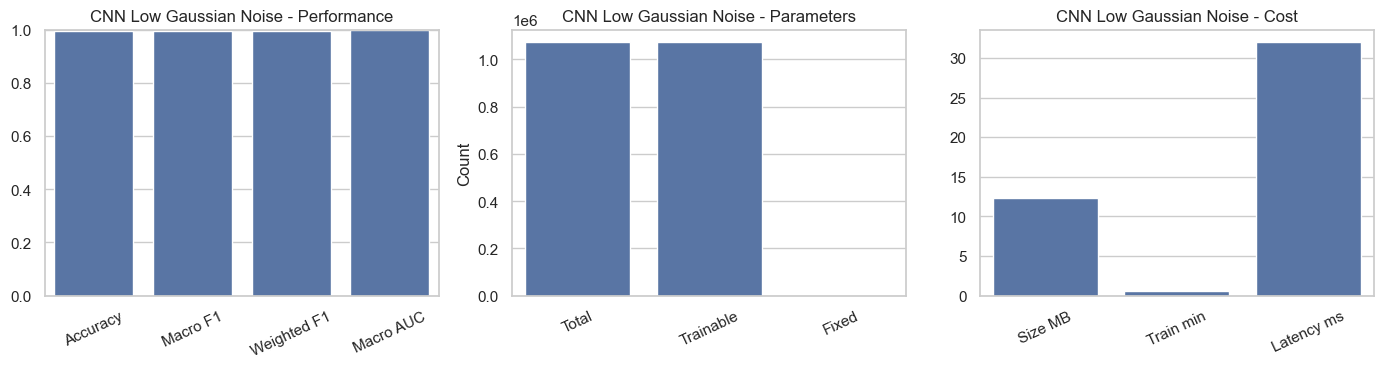

Saved complexity report to: outputs\cnn_low_gaussian_noise\model_performance_complexity.csv
Saved complexity plot to: outputs\cnn_low_gaussian_noise\performance_vs_complexity.png


,model_name,test_accuracy,macro_f1,weighted_f1,macro_auc,weighted_auc,total_parameters,trainable_parameters,non_trainable_parameters,model_size_mb,training_minutes,inference_latency_ms_per_sample
0,CNN Low Gaussian Noise,0.995238,0.995238,0.995238,1.0,1.0,1072839,1072615,224,12.35865,0.570049,31.981572


In [ ]:
def count_trainable_params(model):
    # Count parameters that the model learns during training.
    return int(np.sum([np.prod(weight.shape) for weight in model.trainable_weights]))


def count_non_trainable_params(model):
    # Count parameters that stay fixed, such as batch normalization moving averages.
    return int(np.sum([np.prod(weight.shape) for weight in model.non_trainable_weights]))


def get_model_file_size_mb(model_path):
    # Measure how much disk space the saved model uses.
    model_path = Path(model_path)
    if not model_path.exists():
        return np.nan
    return model_path.stat().st_size / (1024 * 1024)


def measure_inference_latency(model, X_sample, repeats=30):
    # Measure average prediction time for one sample.
    sample = X_sample[:1]

    # Warm-up prediction helps TensorFlow get ready before timing.
    model.predict(sample, verbose=0)

    start_time = time.time()
    for _ in range(repeats):
        model.predict(sample, verbose=0)
    elapsed_seconds = time.time() - start_time

    return (elapsed_seconds / repeats) * 1000


def create_performance_complexity_report(
    model_name,
    model,
    model_path,
    X_latency_sample,
    y_true,
    y_pred,
    evaluation_results,
    training_minutes,
    output_dir,
):
    # Combine model performance and model complexity in one table.
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    _, _, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )

    report = {
        "model_name": model_name,
        "test_accuracy": float(evaluation_results["accuracy"]),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "macro_auc": float(evaluation_results["macro_auc"]),
        "weighted_auc": float(evaluation_results["weighted_auc"]),
        "total_parameters": int(model.count_params()),
        "trainable_parameters": count_trainable_params(model),
        "non_trainable_parameters": count_non_trainable_params(model),
        "model_size_mb": float(get_model_file_size_mb(model_path)),
        "training_minutes": float(training_minutes),
        "inference_latency_ms_per_sample": float(measure_inference_latency(model, X_latency_sample)),
    }

    report_df = pd.DataFrame([report])
    report_path = output_dir / "model_performance_complexity.csv"
    report_df.to_csv(report_path, index=False)

    # Make a simple dashboard-style plot for presentation.
    plt.figure(figsize=(14, 4))

    plt.subplot(1, 3, 1)
    performance_values = [
        report["test_accuracy"],
        report["macro_f1"],
        report["weighted_f1"],
        report["macro_auc"],
    ]
    performance_names = ["Accuracy", "Macro F1", "Weighted F1", "Macro AUC"]
    sns.barplot(x=performance_names, y=performance_values)
    plt.ylim(0, 1)
    plt.title(f"{MODEL_DISPLAY_NAME} - Performance")
    plt.xticks(rotation=25)

    plt.subplot(1, 3, 2)
    complexity_values = [
        report["total_parameters"],
        report["trainable_parameters"],
        report["non_trainable_parameters"],
    ]
    complexity_names = ["Total", "Trainable", "Fixed"]
    sns.barplot(x=complexity_names, y=complexity_values)
    plt.title(f"{MODEL_DISPLAY_NAME} - Parameters")
    plt.ylabel("Count")
    plt.xticks(rotation=25)

    plt.subplot(1, 3, 3)
    speed_values = [
        report["model_size_mb"],
        report["training_minutes"],
        report["inference_latency_ms_per_sample"],
    ]
    speed_names = ["Size MB", "Train min", "Latency ms"]
    sns.barplot(x=speed_names, y=speed_values)
    plt.title(f"{MODEL_DISPLAY_NAME} - Cost")
    plt.xticks(rotation=25)

    plt.tight_layout()
    plot_path = output_dir / "performance_vs_complexity.png"
    plt.savefig(plot_path, dpi=200)
    plt.show()

    print("Saved complexity report to:", report_path)
    print("Saved complexity plot to:", plot_path)
    display(report_df)

    return report_df


MODEL_FAMILY = globals().get("MODEL_FAMILY", "cnn")
COMPLEXITY_OUTPUT_DIR = Path("outputs") / MODEL_FAMILY
LATENCY_X = X_test_model if "X_test_model" in globals() else X_test
MODEL_REPORT_NAME = MODEL_DISPLAY_NAME if "MODEL_DISPLAY_NAME" in globals() else MODEL_FAMILY.upper()

performance_complexity_df = create_performance_complexity_report(
    model_name=MODEL_REPORT_NAME,
    model=best_model,
    model_path=BEST_MODEL_PATH,
    X_latency_sample=LATENCY_X,
    y_true=y_test,
    y_pred=evaluation_results["y_pred"],
    evaluation_results=evaluation_results,
    training_minutes=float(best_row["training_minutes"]),
    output_dir=COMPLEXITY_OUTPUT_DIR,
)